<!-- # Test Logistic Model Fixed Point Equations (with a change point) -->

  0%|          | 0/4 [00:00<?, ?it/s]

δ =  4.1


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/4016 [00:00<?, ?it/s]

ρ:  [[ 0.15179694 -0.00026555]
 [-0.00026555  0.14735109]]
Optimization Results: x =  [4.67517662 1.17624592 0.23720485 4.19803773] , ier =  1 , mesg =  The solution converged. , infodict =  {'nfev': 23, 'njev': 2, 'fjac': array([[-0.00115287,  0.00158593, -0.99813155,  0.06107016],
       [ 0.99712852, -0.02533442,  0.00317013,  0.07129405],
       [ 0.02224432,  0.9987915 ,  0.00423023,  0.04362141],
       [ 0.07237807,  0.04208544, -0.06087252, -0.99462795]]), 'r': array([ 0.54664015, -0.00857222,  0.01100548, -0.63788132, -0.05155274,
        0.00241909,  0.00934365, -0.05147136,  0.00176365, -0.02080504]), 'qtf': array([ 6.63677256e-09, -7.24390745e-09,  5.31411702e-09, -1.11923073e-09]), 'fvec': array([-7.19355682e-09,  5.45463724e-09, -6.55672583e-09,  1.23388873e-09])}
μ̃, σ̃, b =  [1.17624592 0.23720485] 4.198037728242746 4.675176616920775
Optimization Results: x =  [4.81315935 0.54169747 1.23504071 4.30185369] , ier =  1 , mesg =  The solution converged. , infodict =  {'nfev

  0%|          | 0/10 [00:00<?, ?it/s]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.


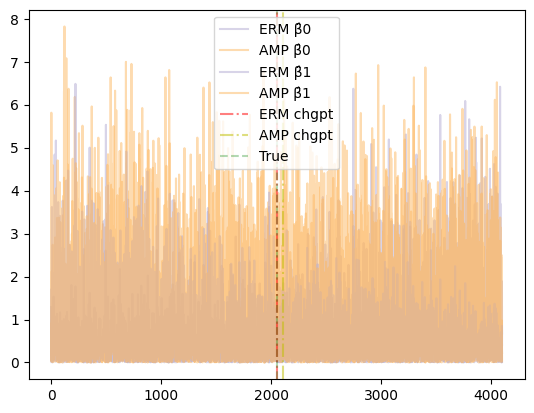

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.


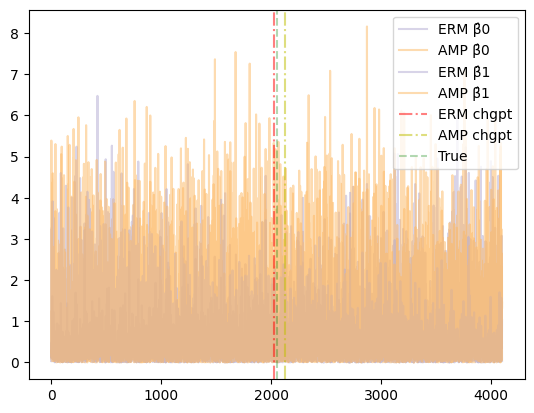

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.


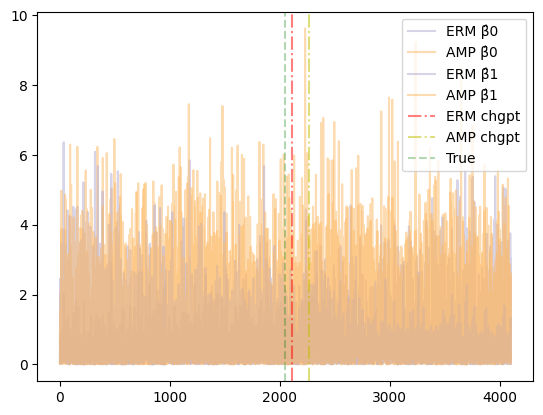

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.


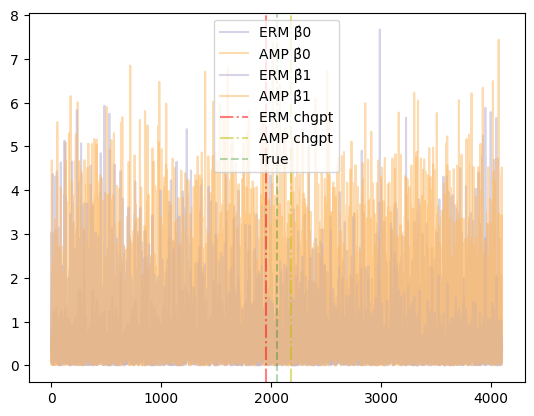

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.


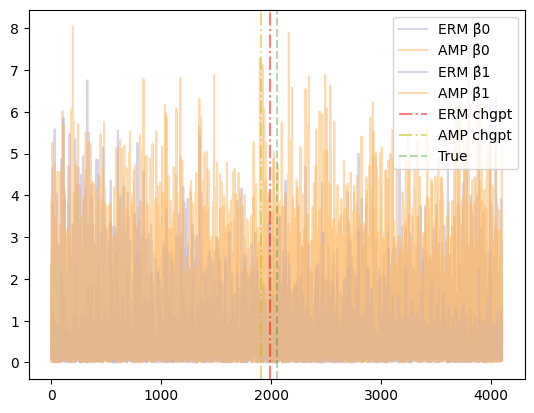

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.


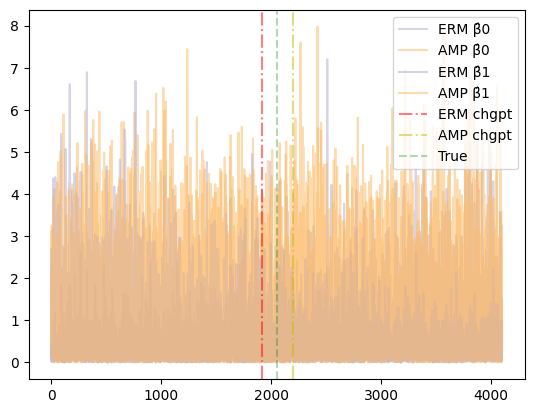

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1


In [2]:
from WERM.config import unif_prior_to_η_ϕ
from WERM.config import η_to_ψ
import WERM.performance_measures
from WERM.signal_priors import GaussianSignal
from WERM.model import *
import WERM
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm import tqdm
from WERM.logistic_fixed_point_eqns import *
from WERM.gof import *
tqdm = partial(tqdm, position=0, leave=True)

np.random.seed(10)

p = 1000
L = 2 # num signals. L-1 changepoints

# δ_list = [1.8, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]
δ_list = [4.1, 4.5, 5.0, 6.5]
num_trials = 10

fractional_chgpt_locations = np.array([0.5])

erm_corr_arr = np.zeros((len(δ_list), num_trials, L))
amp_corr_arr = np.zeros((len(δ_list), num_trials, L))
erm_MSE_arr= np.zeros((len(δ_list), num_trials, L))
amp_MSE_arr= np.zeros((len(δ_list), num_trials, L))
ERM_haus_arr = np.zeros((len(δ_list), num_trials))
AMP_haus_arr = np.zeros((len(δ_list), num_trials))

for i in tqdm(range(len(δ_list))):
    δ = δ_list[i]
    print("δ = ", δ)

    n = int(δ * p)
    if fractional_chgpt_locations.size != 0:
        true_chgpt_locations = lambda n: (n*fractional_chgpt_locations).astype(int)
        C_true = η_to_ψ(true_chgpt_locations(n), n)
    else:
        true_chgpt_locations = lambda n: np.array([])
        C_true = np.zeros(n).astype(int) # No changepoint, assume signal 1, not 0. 

    # --- Preliminaries ---
    # Changepoint locations
    Δ = lambda n: int(n/100)
    Lmin = 2
    Lmax = 2
    # p_l = 1/L * np.ones(L) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
    p_l = None
    num_valid_configs, η_arr, p_η_arr, ϕ = unif_prior_to_η_ϕ(Lmin, Lmax, Δ(n), n, p_l = p_l) # Lxn matrix
    assert η_arr.shape == (num_valid_configs, Lmax-1) and \
        len(p_η_arr) == num_valid_configs
    assert ϕ.shape == (Lmax, n)

    if fractional_chgpt_locations.size == 0:
        # No chgpt prior
        for ℓ_ in range(L):
            ϕ[ℓ_, :] = np.ones(n)

    # Generate a non-identity covariance matrix
    Σ = np.zeros((p, p))
    for i_ in range(p):
        for j_ in range(p):
            # Σ[i_, j_] = 0.4 ** (np.abs(i_ - j_))
            Σ[i_, j_] = 0.0 ** (np.abs(i_ - j_))
    L_chol = scipy.linalg.cholesky(Σ, lower = True)

    # Gaussian Signal Prior
    κ = 0.4
    # covvy = np.block([[1, 0.4], [0.4, 1]])
    covvy = np.eye(L)
    B̃_cov = κ**2 * δ * covvy # keeps the signal power fixed
    signal_prior = GaussianSignal(B̃_cov)

    B̃ = L_chol.T @ signal_prior.sample(p)
    ρ = 1/δ * 1/p * B̃.T @ B̃
    print("ρ: ", ρ)

    μ̃_σ̃_list = []
    for ℓ_ in range(L): 
            π = ϕ[ℓ_, :]
            μ̃, σ̃, b = logistic_fp(π, ρ, L, fractional_chgpt_locations, δ, n)
            print("μ̃, σ̃, b = ", μ̃, σ̃, b)
            μ̃_σ̃_list.append((μ̃, σ̃, b))

    for trial_num in tqdm(range(num_trials)): 

        # Generate the observation vector Y
        X = np.random.normal(0, np.sqrt(1/n), (n, p))

        Θ = X @ B̃
        y = logistic_reg(Θ, C_true).astype(np.float64).flatten()

        # --- Run Weighted ERM and compare with the fixed point equations --- #
        B̂_erm = np.zeros((p, L))
        B̂_amp = np.zeros((p, L))
        Θ̂_amp = np.zeros((n, L))
        β̂_erm_list = [None for ℓ_ in range(L)]
        Z = np.random.multivariate_normal(np.zeros(L), ρ, n)
        ȳ = logistic_reg(Z, C_true).astype(np.float64).flatten()

        for ℓ_ in range(L): 
            π = ϕ[ℓ_, :]
            μ̃, σ̃, b = μ̃_σ̃_list[ℓ_]
            β̂_amp = B̃ @ μ̃ + σ̃ * np.random.randn(p)
            v_Θ = Z @ μ̃ + (σ̃ / np.sqrt(δ)) * np.random.randn(n)
            Θ̂_amp[:, ℓ_] = ḡ_mapped(v_Θ, ȳ, b, π)
            B̂_amp[:, ℓ_] = β̂_amp

            if β̂_erm_list[ℓ_] is None:  # So that we only regress once
                print("Regressing on signal ", ℓ_)
                sample_weight = π
                sk_logistic_reg = linear_model.LogisticRegression(n_jobs = 2, max_iter=int(1e5), penalty = None)
                sk_logistic_reg.fit(X, y, sample_weight = sample_weight)
                print("Done regressing on signal.")
                β̂_erm = sk_logistic_reg.coef_
                β̂_erm_list[ℓ_] = β̂_erm
            else:
                β̂_erm = β̂_erm_list[ℓ_]

            ### --- Compute norm squared correlation --- ###
            B̂_erm[:, ℓ_] = β̂_erm
            erm_corr_arr[i, trial_num, ℓ_] = (WERM.norm_sq_corr(β̂_erm, B̃[:, ℓ_])) # For ERM compute once
            amp_corr_arr[i, trial_num, ℓ_] = (WERM.norm_sq_corr(β̂_amp, B̃[:, ℓ_]))

            ### --- Compute MSE --- ###
            erm_MSE_arr[i, trial_num, ℓ_] = (WERM.MSE(β̂_erm.flatten(), B̃[:, ℓ_]))
            amp_MSE_arr[i, trial_num, ℓ_] = (WERM.MSE(β̂_amp, B̃[:, ℓ_]))

        ## Compute Chgpt estimate for WERM
        PAL = ['#e66101', '#fdb863', '#f7f7f7', '#b2abd2', '#5e3c99']
        for ℓ in range(L):
            plt.plot(np.arange(n), (ζ(X @ B̂_erm[:, ℓ]) - np.multiply(y.flatten(), X @ B̂_erm[:, ℓ])), c = PAL[-1 - ℓ_], alpha = 0.5, label="ERM β̂" + str(ℓ))
            plt.plot(np.arange(n), (ζ(X @ B̂_amp[:, ℓ]) - np.multiply(y.flatten(), X @ B̂_amp[:, ℓ])), c = PAL[0 + ℓ_], alpha = 0.5, label="AMP β̂" + str(ℓ))
            # plt.plot(((Y.flatten() - X @ B̂[:, ℓ])**2), alpha = 0.5, label="Lasso β" + str(ℓ))
        # LR_chgpt_gof_jax_mapped = jax.vmap(LR_chgpt_gof_jax, in_axes=(0, None, None), out_axes=(0, 0))
        opt_chgpt_loc_erm, opt_chgpt_idx_erm = LR_chgpt_gof_jax(X @ B̂_erm, y, η_arr)
        opt_chgpt_loc_amp, opt_chgpt_idx_amp = LR_chgpt_gof_jax(Θ̂_amp, ȳ, η_arr)
        # plot a vertical line at the optimal changepoint location
        [plt.axvline(x=loc, color='r', linestyle='-.', alpha = 0.5, label="ERM chgpt") for loc in opt_chgpt_loc_erm]
        [plt.axvline(x=loc, color='y', linestyle='-.', alpha = 0.5, label="AMP chgpt") for loc in opt_chgpt_loc_amp]
        [plt.axvline(x=c, color='g', linestyle='--', alpha = 0.3, label="True") for c in true_chgpt_locations(n)]
        ERM_haus_arr[i, trial_num] = (1/n * WERM.performance_measures.hausdorff(opt_chgpt_loc_erm, true_chgpt_locations(n)))
        # ERM_size_list.append(len(opt_chgpt_loc_erm[opt_chgpt_loc_erm != -1]))

        # hausdorff_jax_mapped = jax.vmap(hausdorff_jax, in_axes=(0, None)) 
        AMP_haus_arr[i, trial_num] = (1/n * WERM.performance_measures.hausdorff(opt_chgpt_loc_amp, true_chgpt_locations(n)))
        # AMP_size_list.append(len(opt_chgpt_loc_amp[opt_chgpt_loc_amp != -1]))
        # print("Plotting GOF: ")
        # fig = LR_plot_gof_jax(Z, Y.flatten(), η_arr)
        # fig.show()
        # fig = LR_plot_gof(Z, Y.flatten(), η_arr)
        # fig.show()

        plt.legend()
        plt.show()

PAL = ['#1b9e77','#d95f02','#7570b3','#e7298a']
# Sqcorr plots
for ℓ_ in range(L):
    plt.errorbar(δ_list, np.mean(erm_corr_arr[:, :, ℓ_], axis = 1), yerr = np.std(erm_corr_arr[:, :, ℓ_], axis = 1), label="β" + str(ℓ_) + " erm", marker="o", ls="-", c=PAL[ℓ_], alpha = 1.0)
    plt.errorbar(δ_list, np.mean(amp_corr_arr[:, :, ℓ_], axis = 1), yerr = np.std(amp_corr_arr[:, :, ℓ_], axis = 1), label="β" + str(ℓ_) + " amp", marker="x", ls="--", c=PAL[ℓ_], alpha = 0.5)
plt.ylim((0, 1))
plt.xlabel("δ")
plt.ylabel("Norm Sq Corr")
plt.legend()
plt.show()

# MSE plots
for ℓ_ in range(L):
    plt.errorbar(δ_list, np.mean(erm_MSE_arr[:, :, ℓ_], axis = 1), yerr = np.std(erm_MSE_arr[:, :, ℓ_], axis = 1), label="β" + str(ℓ_) + " erm", marker="o", ls="-", c=PAL[ℓ_], alpha = 1.0)
    plt.errorbar(δ_list, np.mean(amp_MSE_arr[:, :, ℓ_], axis = 1), yerr = np.std(amp_MSE_arr[:, :, ℓ_], axis = 1), label="β" + str(ℓ_) + " amp", marker="x", ls="--", c=PAL[ℓ_], alpha = 0.5)
# plt.ylim((0, 2))
plt.xlabel("δ")
plt.ylabel("MSE")
plt.legend()
plt.show()

# Hausdorff plots
δ_arr = np.array([δ_list for _ in range(num_trials)])
plt.errorbar(δ_list, np.mean(ERM_haus_arr, axis = 1), yerr = np.std(ERM_haus_arr, axis = 1), label="ERM", marker="o", ls="-.", c=PAL[1], alpha = 1.0)
plt.errorbar(δ_list, np.mean(AMP_haus_arr, axis = 1), label="Theory", marker=None, ls="-", c=PAL[0], alpha = 1.0)
# plt.scatter(δ_arr, ERM_haus_arr, label="ERM", marker="x", c=PAL[1], alpha = 0.2)
# plt.scatter(δ_arr, AMP_haus_arr, label="AMP", marker="o", c=PAL[0], alpha = 0.2)
plt.ylim((0, 0.35))
plt.xlabel("δ")
plt.ylabel("Hausdorff")
plt.legend()
# plt.savefig("figures/logistic_WERM_L" + str(L) + "_Lstar" + str(chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Logistic model size experiments

In [4]:
from WERM.config import unif_prior_to_η_ϕ, unif_prior_to_η_ϕ_combinations
from WERM.config import η_to_ψ
import WERM.performance_measures
from WERM.signal_priors import GaussianSignal
from WERM.model import *
import WERM
import numpy as np
import jax.numpy as jnp # Not used in any randomness, all randomness is in numpy
import jax
import numpy.random as nprandom
import matplotlib.pyplot as plt
import scipy
from sklearn import linear_model
from functools import partial
from tqdm import tqdm
from WERM.logistic_fixed_point_eqns import *
from WERM.gof import *
tqdm = partial(tqdm, position=0, leave=True)

# np.random.seed(10)

p = 500
L = 3 # num signals. L-1 changepoints

# δ_list = [1.8, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]
# δ_list = [4.1, 5.0, 6.0, 7.0, 8.0, 9.0, 10.0]
# δ_list = [4.1, 4.5, 5.0, 6.5]
# δ_list = [8.0, 9.0, 10.0, 11.0, 12.0, 13.0, 14.0, 15.0]
δ_list = [8.0, 9.0, 10.0, 11.0]
# num_trials = 1
num_trials = 3

fractional_chgpt_locations = np.array([0.5])
# fractional_chgpt_locations = np.array([])

erm_corr_arr = np.zeros((len(δ_list), num_trials, L))
amp_corr_arr = np.zeros((len(δ_list), num_trials, L))
erm_MSE_arr= np.zeros((len(δ_list), num_trials, L))
amp_MSE_arr= np.zeros((len(δ_list), num_trials, L))
ERM_haus_arr = np.zeros((len(δ_list), num_trials))
AMP_haus_arr = np.zeros((len(δ_list), num_trials))
ERM_size_arr = np.zeros((len(δ_list), num_trials))
AMP_size_arr = np.zeros((len(δ_list), num_trials))

for i in tqdm(range(len(δ_list))):
    δ = δ_list[i]
    print("δ = ", δ)

    n = int(δ * p)
    if fractional_chgpt_locations.size != 0:
        true_chgpt_locations = lambda n: (n*fractional_chgpt_locations).astype(int)
        C_true = η_to_ψ(true_chgpt_locations(n), n)
    else:
        true_chgpt_locations = lambda n: np.array([])
        C_true = np.zeros(n).astype(int) # No changepoint, assume signal 1, not 0. 

    # --- Preliminaries ---
    # Changepoint locations
    Δ = lambda n: int(n/5)
    Lmin = 1
    Lmax = L
    p_l = 1/L * np.ones(L) # puts equal weight on all number of signals, set None otherwise. Best for estimating size. 
    num_valid_configs, η_arr, p_η_arr, ϕ = unif_prior_to_η_ϕ_combinations(Lmin, Lmax, Δ(n), n, p_l = p_l) # Lxn matrix
    # p_l = None
    # num_valid_configs, η_arr, p_η_arr, ϕ = unif_prior_to_η_ϕ(Lmin, Lmax, Δ(n), n, p_l = p_l) # Lxn matrix

    # Subsampling
    subsample_factor = 1
    n_subsampled = int(n/subsample_factor)
    _, η_arr_subsampled, p_η_arr_subsampled, _ = unif_prior_to_η_ϕ_combinations(Lmin, Lmax, Δ(n_subsampled), n_subsampled, p_l = p_l) # Lxn matrix
    # _, η_arr_subsampled, p_η_arr_subsampled, _ = unif_prior_to_η_ϕ(Lmin, Lmax, Δ(n_subsampled), n_subsampled, p_l = p_l) # Lxn matrix
    η_arr_subsampled = η_arr_subsampled * subsample_factor # Rescale η_arr_subsampled to match η_arr

    assert η_arr.shape == (num_valid_configs, Lmax-1) and \
        len(p_η_arr) == num_valid_configs
    assert ϕ.shape == (Lmax, n)

    if fractional_chgpt_locations.size == 0:
        # No chgpt prior
        for ℓ_ in range(L):
            ϕ[ℓ_, :] = np.ones(n)

    # Generate a non-identity covariance matrix
    Σ = np.zeros((p, p))
    for i_ in range(p):
        for j_ in range(p):
            Σ[i_, j_] = 0.0 ** (np.abs(i_ - j_))
    L_chol = scipy.linalg.cholesky(Σ, lower = True)

    # Gaussian Signal Prior
    κ = 3.5
    # Design a non-trivial LxL covariance
    covvy = np.zeros((L, L))
    for i_ in range(L):
        for j_ in range(L):
            covvy[i_, j_] = 0.0 ** (np.abs(i_ - j_))
    # covvy = np.block([[1, 0.4], [0.4, 1]])
    B̃_cov = κ**2 * δ * covvy # keeps the signal power fixed
    signal_prior = GaussianSignal(B̃_cov)

    B̃ = L_chol.T @ signal_prior.sample(p)
    ρ = 1/δ * 1/p * B̃.T @ B̃
    print("ρ: ", ρ)

    μ̃_σ̃_list = []
    for ℓ_ in range(L): 
            π = ϕ[ℓ_, :]
            μ̃, σ̃, b = logistic_fp(π, ρ, L, fractional_chgpt_locations, δ, n)
            print("μ̃, σ̃, b = ", μ̃, σ̃, b)
            μ̃_σ̃_list.append((μ̃, σ̃, b))

    for trial_num in tqdm(range(num_trials)): 

        # Generate the observation vector Y
        X = np.random.normal(0, np.sqrt(1/n), (n, p))

        Θ = X @ B̃
        y = logistic_reg(Θ, C_true).astype(np.float64).flatten()

        # --- Run Weighted ERM and compare with the fixed point equations --- #
        B̂_erm = np.zeros((p, L))
        B̂_amp = np.zeros((p, L))
        Θ̂_amp = np.zeros((n, L))
        β̂_erm_list = [None for ℓ_ in range(L)]
        Z = np.random.multivariate_normal(np.zeros(L), ρ, n)
        ȳ = logistic_reg(Z, C_true).astype(np.float64).flatten()

        for ℓ_ in range(L): 
            π = ϕ[ℓ_, :]
            μ̃, σ̃, b = μ̃_σ̃_list[ℓ_]
            β̂_amp = B̃ @ μ̃ + σ̃ * np.random.randn(p)
            v_Θ = Z @ μ̃ + (σ̃ / np.sqrt(δ)) * np.random.randn(n)
            Θ̂_amp[:, ℓ_] = ḡ_mapped(v_Θ, ȳ, b, π)
            B̂_amp[:, ℓ_] = β̂_amp

            if β̂_erm_list[ℓ_] is None:  # So that we only regress once
                print("Regressing on signal ", ℓ_)
                sample_weight = π
                sk_logistic_reg = linear_model.LogisticRegression(n_jobs = 2, max_iter=int(1e5), penalty = None)
                sk_logistic_reg.fit(X, y, sample_weight = sample_weight)
                print("Done regressing on signal.")
                β̂_erm = sk_logistic_reg.coef_
                β̂_erm_list[ℓ_] = β̂_erm
            else:
                β̂_erm = β̂_erm_list[ℓ_]

            ### --- Compute norm squared correlation --- ###
            B̂_erm[:, ℓ_] = β̂_erm
            erm_corr_arr[i, trial_num, ℓ_] = (WERM.norm_sq_corr(β̂_erm, B̃[:, ℓ_])) # For ERM compute once
            amp_corr_arr[i, trial_num, ℓ_] = (WERM.norm_sq_corr(β̂_amp, B̃[:, ℓ_]))

            ### --- Compute MSE --- ###
            erm_MSE_arr[i, trial_num, ℓ_] = (WERM.MSE(β̂_erm.flatten(), B̃[:, ℓ_]))
            amp_MSE_arr[i, trial_num, ℓ_] = (WERM.MSE(β̂_amp, B̃[:, ℓ_]))

        ## Compute Chgpt estimate for WERM
        PAL = ['#e66101', '#fdb863', '#f7f7f7', '#b2abd2', '#5e3c99']
        for ℓ in range(L):
            plt.plot(np.arange(n), (ζ(X @ B̂_erm[:, ℓ]) - np.multiply(y.flatten(), X @ B̂_erm[:, ℓ])), c = PAL[-1 - ℓ_], alpha = 0.5, label="ERM β̂" + str(ℓ))
            plt.plot(np.arange(n), (ζ(X @ B̂_amp[:, ℓ]) - np.multiply(y.flatten(), X @ B̂_amp[:, ℓ])), c = PAL[0 + ℓ_], alpha = 0.5, label="AMP β̂" + str(ℓ))
            # plt.plot(((Y.flatten() - X @ B̂[:, ℓ])**2), alpha = 0.5, label="Lasso β" + str(ℓ))
        # LR_chgpt_gof_jax_mapped = jax.vmap(LR_chgpt_gof_jax, in_axes=(0, None, None), out_axes=(0, 0))
        # opt_chgpt_loc_erm, opt_chgpt_idx_erm = LR_chgpt_gof_jax(X @ B̂_erm, y, η_arr)
        # opt_chgpt_loc_amp, opt_chgpt_idx_amp = LR_chgpt_gof_jax(Θ̂_amp, ȳ, η_arr)

        print("Optimizing gof erm...")
        opt_chgpt_loc_erm = WERM.gof.logistic_reg_opt_chgpt_gof(X @ B̂_erm, y, η_arr_subsampled, p_η_arr_subsampled)
        print("Done optimizing gof erm.")
        print("Optimizing gof amp...")
        opt_chgpt_loc_amp = WERM.gof.logistic_reg_opt_chgpt_gof(Θ̂_amp, ȳ, η_arr_subsampled, p_η_arr_subsampled)
        print("Done optimizing gof amp.")

        # plot a vertical line at the optimal changepoint location
        [plt.axvline(x=loc, color='r', linestyle='-.', alpha = 0.8, label="ERM chgpt") for loc in opt_chgpt_loc_erm]
        [plt.axvline(x=loc, color='y', linestyle='-.', alpha = 0.8, label="AMP chgpt") for loc in opt_chgpt_loc_amp]
        [plt.axvline(x=c, color='g', linestyle='--', alpha = 0.8, label="True") for c in true_chgpt_locations(n)]
        # xs = np.arange(gof_list_erm.shape[0])
        # plt.plot(xs, gof_list_erm, label="ERM GOF")
        # plt.plot(xs, gof_list_amp, label="AMP GOF")

        ERM_haus_arr[i, trial_num] = (1/n * WERM.performance_measures.hausdorff(opt_chgpt_loc_erm, true_chgpt_locations(n)))
        ERM_size_arr[i, trial_num] = (len(opt_chgpt_loc_erm[opt_chgpt_loc_erm != -1]))

        # hausdorff_jax_mapped = jax.vmap(hausdorff_jax, in_axes=(0, None)) 
        AMP_haus_arr[i, trial_num] = (1/n * WERM.performance_measures.hausdorff(opt_chgpt_loc_amp, true_chgpt_locations(n)))
        AMP_size_arr[i, trial_num] = (len(opt_chgpt_loc_amp[opt_chgpt_loc_amp != -1]))
        # print("Plotting GOF: ")
        # fig = LR_plot_gof_jax(Z, Y.flatten(), η_arr)
        # fig.show()
        # fig = LR_plot_gof(Z, Y.flatten(), η_arr)
        # fig.show()

        # plt.ylim((0, 5))
        plt.legend()
        plt.show()

PAL = ['#1b9e77','#d95f02','#7570b3','#e7298a']
# Sqcorr plots
for ℓ_ in range(L):
    plt.errorbar(δ_list, np.mean(erm_corr_arr[:, :, ℓ_], axis = 1), yerr = np.std(erm_corr_arr[:, :, ℓ_], axis = 1), label="β" + str(ℓ_) + " erm", marker="o", ls="-", c=PAL[ℓ_], alpha = 1.0)
    plt.errorbar(δ_list, np.mean(amp_corr_arr[:, :, ℓ_], axis = 1), yerr = np.std(amp_corr_arr[:, :, ℓ_], axis = 1), label="β" + str(ℓ_) + " amp", marker="x", ls="--", c=PAL[ℓ_], alpha = 0.5)
plt.ylim((0, 1))
plt.xlabel("δ")
plt.ylabel("Norm Sq Corr")
plt.legend()
plt.show()

# MSE plots
for ℓ_ in range(L):
    plt.errorbar(δ_list, np.mean(erm_MSE_arr[:, :, ℓ_], axis = 1), yerr = np.std(erm_MSE_arr[:, :, ℓ_], axis = 1), label="β" + str(ℓ_) + " erm", marker="o", ls="-", c=PAL[ℓ_], alpha = 1.0)
    plt.errorbar(δ_list, np.mean(amp_MSE_arr[:, :, ℓ_], axis = 1), yerr = np.std(amp_MSE_arr[:, :, ℓ_], axis = 1), label="β" + str(ℓ_) + " amp", marker="x", ls="--", c=PAL[ℓ_], alpha = 0.5)
# plt.ylim((0, 2))
plt.xlabel("δ")
plt.ylabel("MSE")
plt.legend()
plt.show()

# Hausdorff plots
δ_arr = np.array([δ_list for _ in range(num_trials)])
plt.errorbar(δ_list, np.mean(ERM_haus_arr, axis = 1), yerr = np.std(ERM_haus_arr, axis = 1), label="ERM", marker="o", ls="-.", c=PAL[1], alpha = 1.0)
plt.errorbar(δ_list, np.mean(AMP_haus_arr, axis = 1), label="Theory", marker=None, ls="-", c=PAL[0], alpha = 1.0)
# plt.scatter(δ_arr, ERM_haus_arr, label="ERM", marker="x", c=PAL[1], alpha = 0.2)
# plt.scatter(δ_arr, AMP_haus_arr, label="AMP", marker="o", c=PAL[0], alpha = 0.2)
plt.ylim((0, 0.35))
plt.xlabel("δ")
plt.ylabel("Hausdorff")
plt.legend()
# plt.savefig("figures/logistic_WERM_L" + str(L) + "_Lstar" + str(chgpt_locations.shape[0]) + ".pdf")
plt.show()

# Hausdorff plots
δ_arr = np.array([δ_list for _ in range(num_trials)])
plt.errorbar(δ_list, np.mean(ERM_size_arr, axis = 1), yerr = np.std(ERM_haus_arr, axis = 1), label="ERM", marker="o", ls="-.", c=PAL[1], alpha = 1.0)
plt.errorbar(δ_list, np.mean(AMP_size_arr, axis = 1), label="Theory", marker=None, ls="-", c=PAL[0], alpha = 1.0)
# plt.scatter(δ_arr, ERM_haus_arr, label="ERM", marker="x", c=PAL[1], alpha = 0.2)
# plt.scatter(δ_arr, AMP_haus_arr, label="AMP", marker="o", c=PAL[0], alpha = 0.2)
plt.ylim((0, L + 1))
plt.xlabel("δ")
plt.ylabel("Size")
plt.legend()
# plt.savefig("figures/logistic_WERM_L" + str(L) + "_Lstar" + str(chgpt_locations.shape[0]) + ".pdf")
plt.show()

  0%|          | 0/4 [00:00<?, ?it/s]

δ =  8.0


  0%|          | 0/3 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/2398 [00:00<?, ?it/s]

  0%|          | 0/1276003 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/1276003 [00:00<?, ?it/s]

ρ:  [[12.4144479   0.12952889 -0.83144628]
 [ 0.12952889 12.4327259   0.89882006]
 [-0.83144628  0.89882006 11.05092588]]
Optimization Results: x =  [ 1.68541895  0.44353156  0.22298055 -0.03660339  3.24718178] , ier =  1 , mesg =  The solution converged. , infodict =  {'nfev': 39, 'njev': 4, 'fjac': array([[-2.98293173e-03,  2.11086278e-03,  6.77615034e-04,
        -9.99205428e-01,  3.96824773e-02],
       [-4.99722280e-01,  1.02558165e-01, -1.95870738e-02,
        -3.24293986e-02, -8.59257905e-01],
       [ 2.06111626e-01, -9.50135113e-01, -2.62878934e-02,
        -1.18630121e-02, -2.32227217e-01],
       [-8.88488632e-02, -9.68076801e-03, -9.93311313e-01,
         2.47292867e-03,  7.30662829e-02],
       [-8.36595854e-01, -2.94324509e-01,  1.10713454e-01,
         1.97484041e-02,  4.48143942e-01]]), 'r': array([ 1.46837755e+00, -3.16461295e-01,  2.07710941e-01, -2.36439511e-02,
       -8.41164634e-01,  9.16841273e-02,  1.11548628e-02, -7.32291208e-03,
       -2.51943470e-02,  7.9210

  0%|          | 0/3 [00:00<?, ?it/s]

Regressing on signal  0
Done regressing on signal.
Regressing on signal  1
Done regressing on signal.
Regressing on signal  2
Done regressing on signal.
Optimizing gof erm...


In [ ]:
1/n * hausdorff(opt_chgpt_loc_erm, true_chgpt_locations(n))

0.29

In [ ]:
ERM_haus_arr

array([[0.       , 0.       ],
       [0.2615625, 0.2478125],
       [0.       , 0.       ],
       [0.       , 0.       ],
       [0.       , 0.       ]])